<a href="https://colab.research.google.com/github/Tyna06/MicroServiceUser/blob/main/Mini_apply_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# 1. **** Importer les librairies de base ****
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

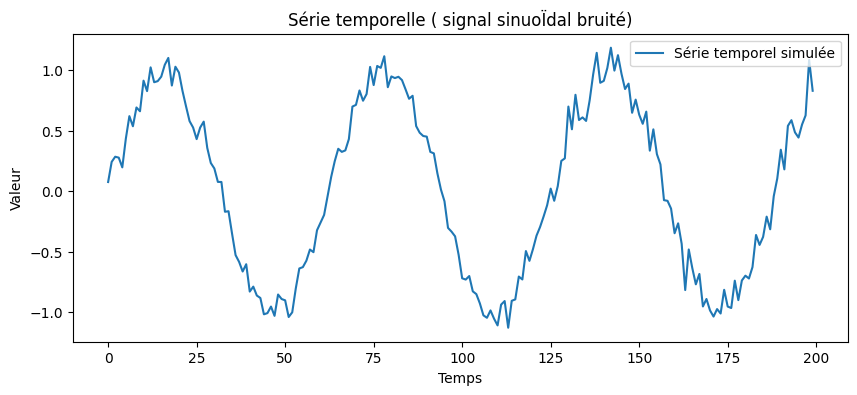

In [9]:
# 2. ****Simuler une TS****
time = np.arange(0, 200) # Création 200 pts dans le temps
series = np.sin(0.1 * time) + np.random.normal(0, 0.1, 200)

# visualisation de la série
plt.figure(figsize=(10,4))
plt.plot(time, series, label="Série temporel simulée")
plt.xlabel("Temps")
plt.ylabel("Valeur")
plt.title("Série temporelle ( signal sinuoÏdal bruité)")
plt.legend()
plt.show()

Phase suivante : Application de CNN
 1. transformer la série en x entrées et y sorties!
 2. création du modèle CNN
---



In [10]:
# 3. ****CNN phase****

# création du dataset x input & y output (TS)
def create_dataset(series, window):
  X, Y = [], []
  for i in range(len(series)-window):
    X.append(series[i:i+window]) # 10 valeur d'entrée
    Y.append(series[i+window]) # valeur suivante à prédire
  return np.array(X), np.array(Y)
window_size = 10
X, y = create_dataset(series, window=window_size)

# Reshape pour Conv1D (samples, time_steps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))
print("Forme de X :", X.shape)
print("Forme de y :", y.shape)

Forme de X : (190, 10, 1)
Forme de y : (190,)


In [11]:
# 4. ****Création du modèle CNN****
model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(10,1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(1) # Sortie : prédiction unique val du jour suivant
])

# Compilation du modèle
model.compile(optimizer='adam',loss='mse')

# résumer de la structure du réseau
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 32)          │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209 (8.63 KB)

 Trainable params: 2,209 (8.63 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 5. ****"Entraînement du modèle "*****
history = model.fit(X,y, epochs=50, validation_split=0.2, verbose=1)


Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0090 - val_loss: 0.0209
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0100 - val_loss: 0.0208
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0087 - val_loss: 0.0211
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0102 - val_loss: 0.0210
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0094 - val_loss: 0.0209
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0096 - val_loss: 0.0205
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0097 - val_loss: 0.0211
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0093 - val_loss: 0.0210
Epoch 9/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0097 - val_loss: 0.0208
Epoch 10/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0084 - val_loss: 0.0210
Epoch 11/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0090 - val_loss: 0.0207
Epoch 12/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0091 - val_loss: 0.0209
E

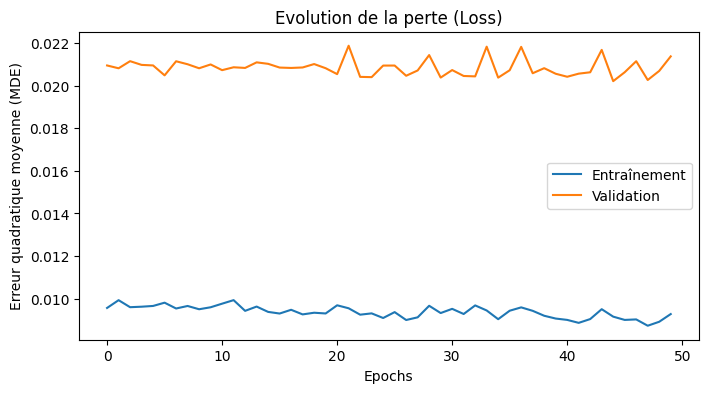

In [15]:
# Visualisation des deux paramètres (loss et val_loss)
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'],label='Entraînement')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Evolution de la perte (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Erreur quadratique moyenne (MDE)')
plt.legend()
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


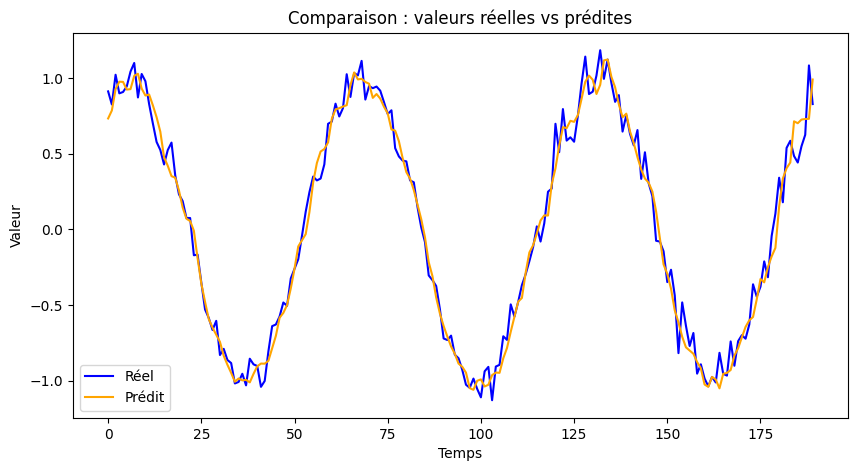

In [16]:
y_pred = model.predict(X)

plt.figure(figsize=(10,5))
plt.plot(y, label='Réel', color='blue')
plt.plot(y_pred, label='Prédit', color='orange')
plt.title('Comparaison : valeurs réelles vs prédites')
plt.xlabel('Temps')
plt.ylabel('Valeur')
plt.legend()
plt.show()